#E23CSEU0868
# Lab-6
#B-29


In [2]:
!pip install -q kagglehub scikit-image seaborn

In [3]:
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [4]:
import os

for root, dirs, files in os.walk(path):
    print(root, "->", len(files), "files")
    if len(files) > 0:
        print("Sample files:", files[:3])

/kaggle/input/chest-xray-pneumonia -> 0 files
/kaggle/input/chest-xray-pneumonia/chest_xray -> 0 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray -> 1 files
Sample files: ['.DS_Store']
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val -> 1 files
Sample files: ['.DS_Store']
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA -> 9 files
Sample files: ['person1947_bacteria_4876.jpeg', 'person1946_bacteria_4875.jpeg', 'person1952_bacteria_4883.jpeg']
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL -> 9 files
Sample files: ['NORMAL2-IM-1431-0001.jpeg', 'NORMAL2-IM-1440-0001.jpeg', 'NORMAL2-IM-1442-0001.jpeg']
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test -> 1 files
Sample files: ['.DS_Store']
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA -> 390 files
Sample files: ['person1676_virus_2892.jpeg', 'person1650_virus_2852.jpeg', 'person22_virus_55.jpeg']
/kaggle/input/chest-xray-pneumonia/ch

In [5]:
import os
import glob

image_paths = []
labels = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith((".jpeg", ".jpg", ".png")):

            full_path = os.path.join(root, file)

            if "NORMAL" in root.upper():
                label = 0
            elif "PNEUMONIA" in root.upper():
                label = 1
            else:
                continue

            image_paths.append(full_path)
            labels.append(label)

print("Total images:", len(image_paths))
print("Normal:", labels.count(0))
print("Pneumonia:", labels.count(1))

Total images: 17568
Normal: 4749
Pneumonia: 12819


In [6]:
import pandas as pd

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df["class"] = df["label"].map({
    0: "Normal",
    1: "Pneumonia"
})

print(df["class"].value_counts())

class
Pneumonia    12819
Normal        4749
Name: count, dtype: int64


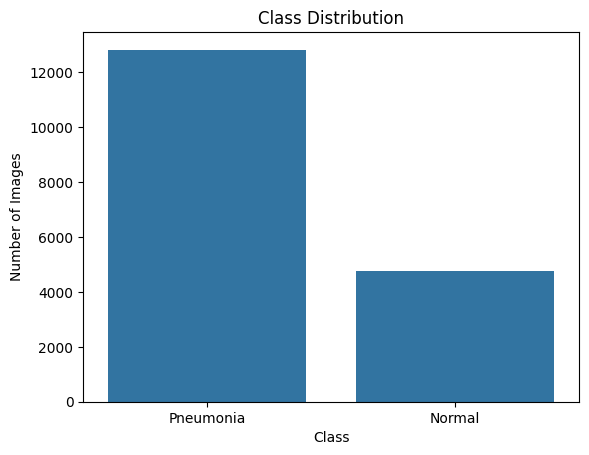

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="class")

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [8]:
import os
import pandas as pd

image_paths = []
labels = []

for root, dirs, files in os.walk(path):

    if "__MACOSX" in root:
        continue

    for file in files:

        if file.startswith("._"):
            continue

        if file.lower().endswith((".jpeg", ".jpg", ".png")):

            full_path = os.path.join(root, file)

            if "NORMAL" in root.upper():
                label = 0

            elif "PNEUMONIA" in root.upper():
                label = 1

            else:
                continue

            image_paths.append(full_path)
            labels.append(label)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df["class"] = df["label"].map({
    0: "Normal",
    1: "Pneumonia"
})

print("Total images:", len(df))
print("\nClass distribution:")
print(df["class"].value_counts())

Total images: 11712

Class distribution:
class
Pneumonia    8546
Normal       3166
Name: count, dtype: int64


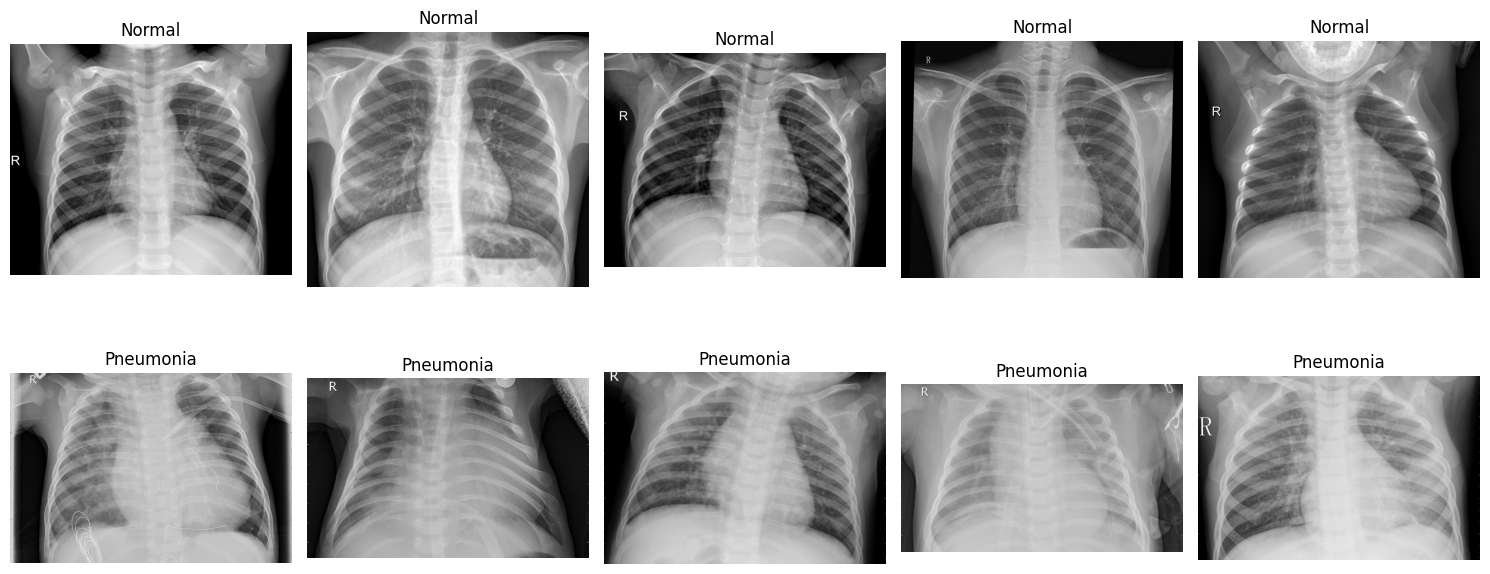

In [9]:
import random
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, class_name in enumerate(["Normal", "Pneumonia"]):

    class_images = df[
        df["class"] == class_name
    ]["image_path"].tolist()

    selected_images = random.sample(class_images, 5)

    for col, img_path in enumerate(selected_images):

        img = Image.open(img_path)

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [10]:
IMG_SIZE = (128, 128)

def load_image(path):
    img = Image.open(path).convert("L")
    img = img.resize(IMG_SIZE)

    return np.array(img)

Image shape: (128, 128)


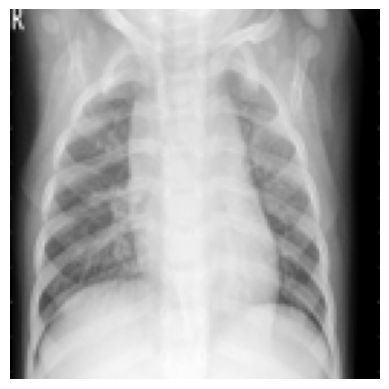

In [11]:
import numpy as np
import matplotlib.pyplot as plt

sample = load_image(image_paths[0])

print("Image shape:", sample.shape)

plt.imshow(sample, cmap="gray")
plt.axis("off")
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X_paths = df["image_path"].values
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X_paths,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 8198
Validation: 1757
Testing: 1757


In [13]:
print("Train percentage:", len(X_train)/len(X_paths)*100)
print("Validation percentage:", len(X_val)/len(X_paths)*100)
print("Test percentage:", len(X_test)/len(X_paths)*100)

Train percentage: 69.99658469945356
Validation percentage: 15.001707650273225
Test percentage: 15.001707650273225


In [14]:
from skimage.feature import hog

def extract_hog(image):

    features = hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features

In [15]:
img = load_image(X_train[0])

hog_features = extract_hog(img)

print("HOG feature vector shape:", hog_features.shape)

HOG feature vector shape: (8100,)


In [16]:
from skimage.feature import local_binary_pattern

def extract_lbp(image):

    radius = 1
    points = 8 * radius

    lbp = local_binary_pattern(
        image,
        points,
        radius,
        method="uniform"
    )

    n_bins = points + 2

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins),
        density=True
    )

    return histogram

In [17]:
lbp_features = extract_lbp(img)

print("LBP feature vector shape:", lbp_features.shape)

LBP feature vector shape: (10,)


In [18]:
from skimage.feature import graycomatrix, graycoprops

def extract_glcm(image):

    image_small = (image / 32).astype(np.uint8)

    glcm = graycomatrix(
        image_small,
        distances=[1],
        angles=[0],
        levels=8,
        symmetric=True,
        normed=True
    )

    features = [
        graycoprops(glcm, "contrast")[0, 0],
        graycoprops(glcm, "dissimilarity")[0, 0],
        graycoprops(glcm, "homogeneity")[0, 0],
        graycoprops(glcm, "energy")[0, 0],
        graycoprops(glcm, "correlation")[0, 0],
        graycoprops(glcm, "ASM")[0, 0]
    ]

    return np.array(features)

In [19]:
glcm_features = extract_glcm(img)

print("GLCM feature vector:", glcm_features)
print("GLCM feature vector shape:", glcm_features.shape)

GLCM feature vector: [0.31576033 0.27073081 0.86909413 0.33036624 0.94460939 0.10914185]
GLCM feature vector shape: (6,)


In [20]:
def extract_all_features(path):

    image = load_image(path)

    hog_features = extract_hog(image)
    lbp_features = extract_lbp(image)
    glcm_features = extract_glcm(image)

    combined = np.concatenate([
        hog_features,
        lbp_features,
        glcm_features
    ])

    return combined

In [21]:
from tqdm import tqdm

def create_feature_dataset(paths):

    features = []

    for path in tqdm(paths):

        feature_vector = extract_all_features(path)

        features.append(feature_vector)

    return np.array(features)

In [22]:
X_train_features = create_feature_dataset(X_train)
X_val_features = create_feature_dataset(X_val)
X_test_features = create_feature_dataset(X_test)

print("Training feature shape:", X_train_features.shape)
print("Validation feature shape:", X_val_features.shape)
print("Testing feature shape:", X_test_features.shape)

100%|██████████| 1757/1757 [00:38<00:00, 45.79it/s]

Training feature shape: (8198, 8116)
Validation feature shape: (1757, 8116)
Testing feature shape: (1757, 8116)


In [23]:
def prepare_cnn_data(paths):

    images = []

    for path in tqdm(paths):

        img = Image.open(path).convert("L")
        img = img.resize(IMG_SIZE)

        img = np.array(img) / 255.0

        images.append(img)

    images = np.array(images)

    images = images.reshape(
        images.shape[0],
        128,
        128,
        1
    )

    return images

In [24]:
X_train_cnn = prepare_cnn_data(X_train)
X_val_cnn = prepare_cnn_data(X_val)
X_test_cnn = prepare_cnn_data(X_test)

print(X_train_cnn.shape)
print(X_val_cnn.shape)
print(X_test_cnn.shape)

100%|██████████| 1757/1757 [00:19<00:00, 90.97it/s]


(8198, 128, 128, 1)
(1757, 128, 128, 1)
(1757, 128, 128, 1)


In [25]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

cnn_model = Sequential([

    Input(shape=(128, 128, 1)),

    Conv2D(32, (3,3), activation="relu"),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation="relu"),
    MaxPooling2D((2,2)),

    Conv2D(128, (3,3), activation="relu"),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [27]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - accuracy: 0.8736 - loss: 0.2972 - val_accuracy: 0.9402 - val_loss: 0.1554
Epoch 2/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9368 - loss: 0.1650 - val_accuracy: 0.9454 - val_loss: 0.1379
Epoch 3/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9512 - loss: 0.1360 - val_accuracy: 0.9585 - val_loss: 0.1123
Epoch 4/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9623 - loss: 0.1083 - val_accuracy: 0.9641 - val_loss: 0.1008
Epoch 5/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9644 - loss: 0.0993 - val_accuracy: 0.9676 - val_loss: 0.0965
Epoch 6/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9694 - loss: 0.0826 - val_accuracy: 0.9659 - val_loss: 0.1031
Epoch 7/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9726 - loss: 0.0710 - val_accuracy: 0.9698 - val_loss: 0.0849
Epoch 8/15
257/257 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9800 - loss: 0.0571 - val_acc

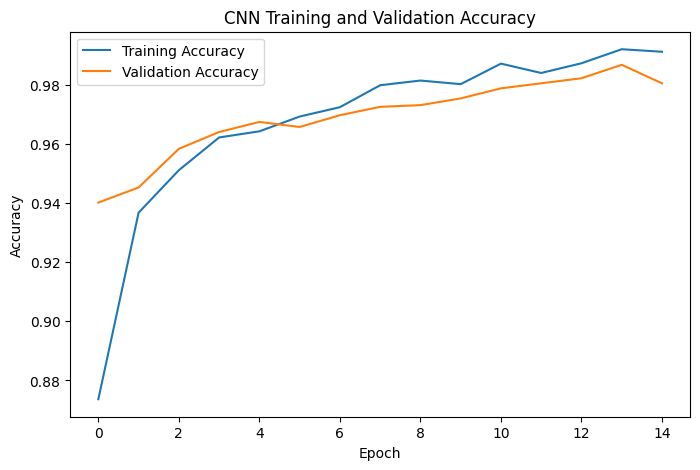

In [28]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()

plt.show()

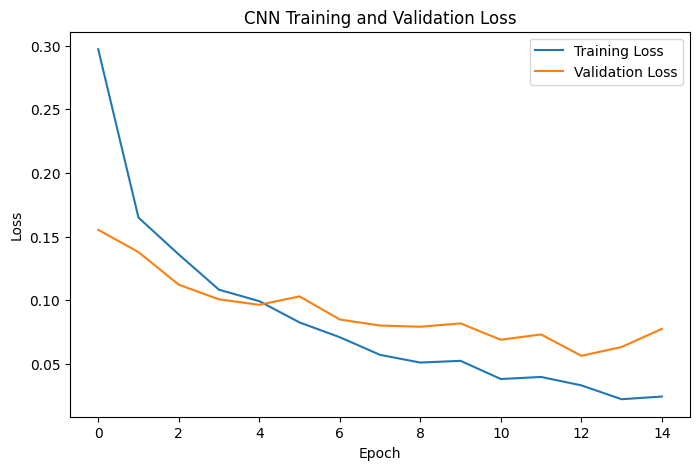

In [29]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()

plt.show()

In [30]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.06061619892716408
Test Accuracy: 0.980079710483551


In [31]:
y_probability = cnn_model.predict(X_test_cnn).ravel()

y_pred = (y_probability >= 0.5).astype(int)

print("Predictions:", y_pred[:20])

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Predictions: [1 0 1 1 1 1 1 1 0 0 0 1 1 0 1 0 1 1 1 1]


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9800796812749004
Precision: 0.9829589465530596
Recall   : 0.9898595943837754
F1 Score : 0.9863972017100661


In [33]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Pneumonia"]
    )
)

              precision    recall  f1-score   support

      Normal       0.97      0.95      0.96       475
   Pneumonia       0.98      0.99      0.99      1282

    accuracy                           0.98      1757
   macro avg       0.98      0.97      0.97      1757
weighted avg       0.98      0.98      0.98      1757



In [34]:
from sklearn.metrics import roc_auc_score, roc_curve

auc = roc_auc_score(y_test, y_probability)

print("AUROC:", auc)

AUROC: 0.997205025043107


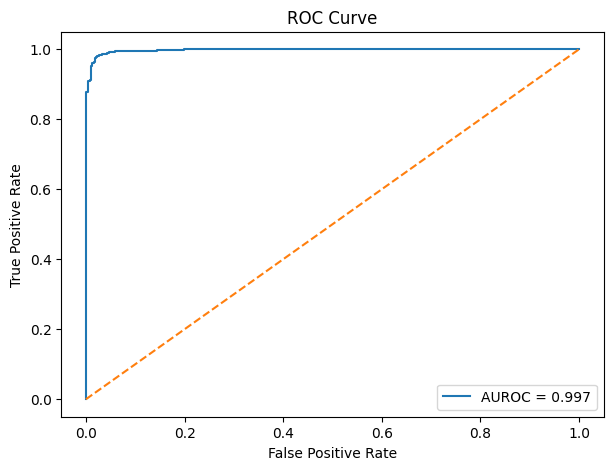

In [35]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, label=f"AUROC = {auc:.3f}")

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[ 453   22]
 [  13 1269]]


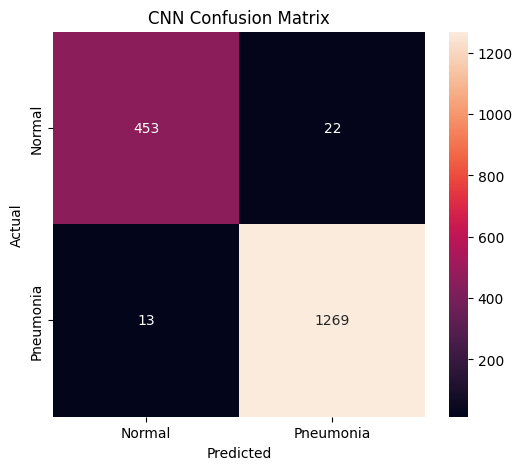

In [37]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Normal", "Pneumonia"],
    yticklabels=["Normal", "Pneumonia"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")

plt.show()

In [38]:
def create_cnn(filters=32, dropout=0.5, learning_rate=0.001):

    model = Sequential([

        Input(shape=(128,128,1)),

        Conv2D(filters, (3,3), activation="relu"),
        MaxPooling2D((2,2)),

        Conv2D(filters*2, (3,3), activation="relu"),
        MaxPooling2D((2,2)),

        Conv2D(filters*4, (3,3), activation="relu"),
        MaxPooling2D((2,2)),

        Flatten(),

        Dense(128, activation="relu"),
        Dropout(dropout),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [39]:
configs = [
    {"filters": 16, "dropout": 0.3, "learning_rate": 0.001},
    {"filters": 32, "dropout": 0.5, "learning_rate": 0.001},
    {"filters": 64, "dropout": 0.5, "learning_rate": 0.0005}
]

results = []

for config in configs:

    print("\nTesting:", config)

    model = create_cnn(
        filters=config["filters"],
        dropout=config["dropout"],
        learning_rate=config["learning_rate"]
    )

    history_temp = model.fit(
        X_train_cnn,
        y_train,
        validation_data=(X_val_cnn, y_val),
        epochs=5,
        batch_size=32,
        verbose=0
    )

    best_val_accuracy = max(
        history_temp.history["val_accuracy"]
    )

    results.append({
        "Configuration": config,
        "Best Validation Accuracy": best_val_accuracy
    })

results_df = pd.DataFrame(results)

results_df


Testing: {'filters': 16, 'dropout': 0.3, 'learning_rate': 0.001}

Testing: {'filters': 32, 'dropout': 0.5, 'learning_rate': 0.001}

Testing: {'filters': 64, 'dropout': 0.5, 'learning_rate': 0.0005}


,Configuration,Best Validation Accuracy
0,"{'filters': 16, 'dropout': 0.3, 'learning_rate...",0.966989
1,"{'filters': 32, 'dropout': 0.5, 'learning_rate...",0.966420
2,"{'filters': 64, 'dropout': 0.5, 'learning_rate...",0.965282


In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(
    X_train_features,
    y_train
)

logistic_pred = logistic_model.predict(X_test_features)

print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=["Normal", "Pneumonia"]
    )
)

              precision    recall  f1-score   support

      Normal       0.96      0.97      0.97       475
   Pneumonia       0.99      0.99      0.99      1282

    accuracy                           0.98      1757
   macro avg       0.98      0.98      0.98      1757
weighted avg       0.98      0.98      0.98      1757



In [41]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
import numpy as np

rng = np.random.RandomState(42)

normal_idx = np.where(y_train == 0)[0]
pneumonia_idx = np.where(y_train == 1)[0]

n_per_class = min(
    1000,
    len(normal_idx),
    len(pneumonia_idx)
)

sample_idx = np.concatenate([
    rng.choice(normal_idx, n_per_class, replace=False),
    rng.choice(pneumonia_idx, n_per_class, replace=False)
])

X_svm_train = X_train_features[sample_idx]
y_svm_train = y_train[sample_idx]

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="linear",
        probability=False,
        cache_size=1000
    ))
])

svm_model.fit(X_svm_train, y_svm_train)

svm_pred = svm_model.predict(X_test_features)

print(classification_report(
    y_test,
    svm_pred,
    target_names=["Normal", "Pneumonia"]
))


              precision    recall  f1-score   support

      Normal       0.88      0.96      0.92       475
   Pneumonia       0.98      0.95      0.97      1282

    accuracy                           0.95      1757
   macro avg       0.93      0.95      0.94      1757
weighted avg       0.96      0.95      0.95      1757



In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "CNN": y_pred,
    "Logistic Regression": logistic_pred,
    "SVM": svm_pred
}

comparison = []

for name, predictions in models.items():

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,CNN,0.980080,0.982959,0.989860,0.986397
1,Logistic Regression,0.982925,0.989828,0.986739,0.988281
2,SVM,0.953330,0.983871,0.951638,0.967486
